# LeetCode #152: Maximum Product Subarray

https://leetcode.com/problems/maximum-product-subarray/

## Three ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute force: every start, every end** | $O(n^2)$ | $O(1)$ | 20,000 numbers is about 200 million products. Too slow. |
| **Products from the left and from the right** | $O(n)$ | $O(1)$ | Two passes over the array, resetting at every zero. |
| **Carry the biggest and the smallest product ★** | $O(n)$ | $O(1)$ | One pass, three numbers remembered. |

`n` is the length of `nums`. $O(n)$ means **the work grows in step with the length**: 20,000 numbers is
about 20,000 steps. $O(n^2)$ means it grows with the square: double the length, four times the work.
$O(1)$ means the memory doesn't grow at all.

A **subarray** is a run of neighbouring numbers, at least one long: `[3,-2]` is a subarray of
`[2,3,-2,4]`, but `[2,-2]` is not.

## Understanding the methods

### Brute force

Fix each start, extend the end one step at a time, keep multiplying and remember the largest product
seen. It's correct, but it looks at every pair of start and end.

### Products from the left and from the right

Multiply from the left, restarting after every zero, and do the same from the right; the answer is the
largest running product seen in either pass. It works because, between zeros, the best run either keeps
every number or drops everything up to the first negative or after the last one. Correct, but it takes
two passes and an argument most people can't rebuild under pressure.

### Optimal: carry the biggest and the smallest product ★ (the one coded below)

At each position keep two numbers: the **biggest** and the **smallest** product of a run that ends right
here. Multiplying by a negative turns the smallest into the biggest, so the smallest is worth keeping. Each
new pair comes from the number alone, or the number times one of the previous pair. Building each answer
from the one just before it is called **dynamic programming**.

**Why this beats the two-pass version:** one pass, and every step is the same small rule, with no
separate argument about where the negatives are.

**Constraints:**
* `1 <= nums.length <= 2 * 10^4`
* `-10 <= nums[i] <= 10`
* The product of any subarray of `nums` is guaranteed to fit in a 32-bit integer


## Explain Like I'm a Newbie

### What the question is actually asking

Pick a run of neighbouring numbers and multiply them. Which run gives the biggest product?

```
[2, 3, -2, 4]      2 × 3 = 6        best
                   2 × 3 × -2 × 4 = -48
                   4 = 4
```

### The one idea you need: the worst product can become the best

For the biggest **sum** of a run, you'd carry "the best sum ending here" and either extend it or start
again. Try that with products and it breaks, because of negatives. In `[-2, 3, -4]` the best run is the
whole thing, 24. But at the 3, the best product ending there is 3, and `-2 × 3 = -6` looks like rubbish
to throw away. That `-6` is exactly what the `-4` needs: `-6 × -4 = 24`.

So carry two numbers at every position:

> **`max_p` = the biggest product of a run that ends exactly here; `min_p` = the smallest.**

Each new one is the number on its own (start a fresh run), or the number times the previous `max_p`, or
times the previous `min_p`. A negative number swaps which of those wins: big times negative is very
negative, very negative times negative is big.

### What that means in code

When `n` is negative, swap `max_p` and `min_p` first. Then `max_p = max(n, max_p * n)` and `min_p =
min(n, min_p * n)` are both right. Keep a separate `result` for the best `max_p` seen anywhere. A zero
needs no special case: both products become 0, and the next number starts fresh because `n` on its own
beats `0 × n`.

### Mistakes people make the first time

1. **Tracking only the biggest.** Passes both of LeetCode's samples (`[2,3,-2,4]` and `[-2,0,-1]`). On
   `[-2,3,-4]` it returns 3 instead of 24.
2. **Updating in place without a swap or a saved copy.** Writing `max_p = max(n, max_p*n, min_p*n)` and
   then `min_p = min(n, max_p*n, min_p*n)` uses the *new* `max_p` in the second line. It passes both samples,
   then answers 1440 instead of 120 on `[-2,-3,-4,-5]`.
3. **Starting `result` at 0.** `[-2]` must answer -2: the run has to contain at least one number.

### Things worth knowing

LeetCode promises every product fits in 32 bits. Without that, 20,000 numbers up to 10 would overflow any
integer type, and the safe fix would be to compare logarithms or use big integers.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "It looks like maximum subarray sum, but a negative number turns the smallest product into the largest. So at each position I carry two things: the biggest and the smallest product of a run ending there. Each comes from the number alone, or the number times one of the previous pair, and if the number is negative I swap the pair first. A separate running best takes the maximum. One pass, three variables. It leans on the products fitting in an int, which the problem promises."

The trap, the two values, the swap and the honest assumption. If I hear those, I know the code will be right.

---

### I slide the problem across the table

I write `[2, 3, -2, 4]` and ask for the largest product of a contiguous subarray.

> **You:** "So 2 times 3 is 6, and anything that crosses the -2 goes negative. Six. Can there be zeros? And does the subarray have to be non-empty?"

**"Zeros, yes. Non-empty, yes. `[-2]` answers -2."** That second answer matters more than it looks. It decides how you initialise the running best, and I'll check it on the board.

> **You:** "What's the range? With twenty thousand numbers the product could get enormous."

**"Values are between -10 and 10, and every subarray's product fits in 32 bits."** Good. You noticed the product can explode before writing a line. That's the assumption I'll want you to name at the end.

---

### Now tell me what's actually hard about it

> **You:** "If this were sums, I'd carry the best sum ending here and either extend it or restart. With products that fails on `[-2, 3, -4]`. At the 3, the best product ending there is 3, so I'd throw away -6. But -6 times -4 is 24, the real answer."

> **You:** "So the smallest product isn't junk. It's the biggest one waiting for a negative. I need to carry both."

That's the hard part, with an input built to break the obvious approach, before the word "dynamic programming" comes up. It tells me you're reasoning, not recalling.

I sometimes push: "and what does a zero do to your two numbers?"

> **You:** "Both become zero, which is right, since every run that ends at a zero multiplies to zero. Then the next number starts fresh, because n on its own beats zero times n. So zeros don't need their own case, and I'd rather not add flags for them."

---

### Before you touch the board, tell me the shape and the cost

> **You:** "max_p is the biggest product of a run that ends exactly at the current index, min_p the smallest. For the next number n, the candidates are n alone, max_p times n, and min_p times n. The biggest of those is the new max_p, the smallest is the new min_p. If n is negative, I swap max_p and min_p first, so the two-way max and min line up. A zero makes both zero, and the next number restarts because it beats zero times itself.
>
> One pass with constant work per number: 20,000 numbers, 20,000 steps. Trying every start and end would be about 200 million products."

The cost comes from the loop. And defining exactly what max_p means, "ending exactly here", is what makes the recurrence obviously right instead of plausible.

---

### Now whiteboard it

```
max_p = min_p = result = nums[0]
```

> **You:** "Start from the first number, not zero, because the run must be non-empty. With `[-2]`, a zero start would answer 0."

That's the line I watch. Write `result = 0` silently and I'll hand you `[-2]`.

```
for n in nums[1:]:
    if n < 0:
        max_p, min_p = min_p, max_p
```

> **You:** "Times a negative, the old biggest becomes the new smallest and the other way round. Swapping first means the next two lines only ever need two candidates each."

If you skip the swap, I'll ask how you avoid using a value you've already overwritten. Most people who skip it compute min_p from the new max_p and don't notice.

```
    max_p = max(n, max_p * n)
    min_p = min(n, min_p * n)
    result = max(result, max_p)
return result
```

> **You:** "n on its own means starting a fresh run here, which is what saves me after a zero. The best can end anywhere, so result tracks the biggest max_p seen."

---

### Walk me through it before you say you're done

> **You:** "On `[2, 3, -2, 4]`. Start at 2, 2, 2. The 3: max is 6, min is 3, best 6. The -2: swap to 3 and 6, then max is -2 on its own, min is 6 times -2, -12. Best stays 6. The 4: max is 4, min is -48. Best 6."

> **You:** "If there were a -1 on the end, the swap would put -48 in max_p and -1 times -48 gives 48. That's why I kept the -48."

That last sentence is the one I'm hoping for: the dry-run shows the stored minimum paying off.

> **You:** "And `[-2]` from your clarifier: the loop never runs, so it returns -2."

---

### Then tell me where it breaks, before I ask

> **You:** "Time and memory can't improve: I have to look at every number once, and I keep three. What it leans on is your promise that products fit in 32 bits. Without it, twenty thousand nines overflow every integer type, and then I'd either compare sums of logarithms, which loses exactness, or use big integers, which makes each multiply slower."

> **You:** "If you wanted the subarray itself and not just the product, I'd carry a start index alongside max_p and min_p. They swap together with the values, and they reset to the current index whenever n on its own wins."

That's the generalisation I'd ask for next, answered before I asked. It also shows you understand the swap is a swap of two whole states, not of two numbers.

---

### What would worry me

Carrying only the maximum and defending it because both samples pass. A three-way max followed by a three-way min that reads the max it just overwrote. Special-casing zeros with resets and flags when the "n alone" option already covers them. And starting the best at zero.


## Solutions

All four carry the biggest and smallest product of a run ending at the current number, swapping the two when the number is negative.

### C#


In [ ]:
public class Solution {
    public int MaxProduct(int[] nums) {
        // maxProd / minProd = biggest / smallest product of a run that ENDS at the current index.
        // Start from nums[0], not 0: a run has at least one number, so [-2] must answer -2.
        int maxProd = nums[0], minProd = nums[0], result = nums[0];
        for (int i = 1; i < nums.Length; i++) {
            // Times a negative, the biggest becomes the smallest and vice versa,
            // so swap first; then each update below needs only two candidates
            if (nums[i] < 0) (maxProd, minProd) = (minProd, maxProd);
            // nums[i] alone = start a fresh run here (this is also what recovers after a 0)
            maxProd = Math.Max(nums[i], maxProd * nums[i]);
            minProd = Math.Min(nums[i], minProd * nums[i]);
            // The best run can end anywhere, so remember the biggest maxProd ever seen
            result = Math.Max(result, maxProd);
        }
        return result;
    }
}

### Python


In [ ]:
from typing import List

class Solution:
    def maxProduct(self, nums: List[int]) -> int:
        # max_p / min_p = biggest / smallest product of a run that ENDS at the current number.
        # Start from nums[0], not 0: a run has at least one number, so [-2] must answer -2.
        max_p = min_p = result = nums[0]
        for n in nums[1:]:
            # Times a negative, the biggest becomes the smallest and vice versa,
            # so swap first; then each update below needs only two candidates
            if n < 0:
                max_p, min_p = min_p, max_p
            # n alone = start a fresh run here (this is also what recovers after a 0)
            max_p = max(n, max_p * n)
            min_p = min(n, min_p * n)
            # The best run can end anywhere, so remember the biggest max_p ever seen
            result = max(result, max_p)
        return result

### Go

Go only gained a built-in `max` and `min` for numbers in version 1.21, so the two updates are written out as `if`/`else`. The `main` function just lets the file run on its own.


In [ ]:
package main

import "fmt"

func maxProduct(nums []int) int {
    // maxP / minP = biggest / smallest product of a run that ENDS at the current number.
    // Start from nums[0], not 0: a run has at least one number, so [-2] must answer -2.
    maxP, minP, result := nums[0], nums[0], nums[0]
    for _, n := range nums[1:] {
        // Times a negative, the biggest becomes the smallest and vice versa,
        // so swap first; then each update below needs only two candidates
        if n < 0 {
            maxP, minP = minP, maxP
        }
        // n alone = start a fresh run here (this is also what recovers after a 0)
        if n > maxP*n {
            maxP = n
        } else {
            maxP = maxP * n
        }
        if n < minP*n {
            minP = n
        } else {
            minP = minP * n
        }
        // The best run can end anywhere, so remember the biggest maxP ever seen
        if maxP > result {
            result = maxP
        }
    }
    return result
}

func main() {
    fmt.Println(maxProduct([]int{2, 3, -2, 4})) // 6
}

### Rust


In [ ]:
pub struct Solution;

impl Solution {
    pub fn max_product(nums: Vec<i32>) -> i32 {
        // max_p / min_p = biggest / smallest product of a run that ENDS at the current number.
        // Start from nums[0], not 0: a run has at least one number, so [-2] must answer -2.
        let (mut max_p, mut min_p, mut result) = (nums[0], nums[0], nums[0]);
        for &n in &nums[1..] {
            // Times a negative, the biggest becomes the smallest and vice versa,
            // so swap first; then each update below needs only two candidates
            if n < 0 {
                std::mem::swap(&mut max_p, &mut min_p);
            }
            // n alone = start a fresh run here (this is also what recovers after a 0)
            max_p = n.max(max_p * n);
            min_p = n.min(min_p * n);
            // The best run can end anywhere, so remember the biggest max_p ever seen
            result = result.max(max_p);
        }
        result
    }
}

## Example Scenarios

### 1. Common Case — One Sign Flip
**Input:** `nums = [2,3,-2,4]`

The biggest product climbs from 2 to 6, then the -2 makes every run through it negative, so the biggest
restarts at -2 and then 4. Nothing beats the 6 from `[2,3]`. **Output:** `6`

### 2. Slightly Complex — A Zero Resets Everything
**Input:** `nums = [-2,0,-1]`

The 0 turns both the biggest and the smallest into 0, so no run can carry across it. The -1 after it starts
fresh at -1, and 0 is the best seen. **Output:** `0`

### 3. Edge Case: Time Factor — Two Negatives Multiply Up
**Input:** `nums = [-2,3,-4]`

The input is tiny; every input costs one step per number, so this one stands in for the mechanism, not the
worst case. The smallest product, `-2 × 3 = -6`, is carried along, and at the -4 it flips into the biggest.
**Output:** `24`

### 4. Edge Case: Space Factor — Constant Tracking, Tiny Input
**Input:** `nums = [3,-1,4]`

The solution keeps three numbers whatever the input, so no input is harder on memory. Here every run that
crosses the -1 is negative, so the lone 4 wins. **Output:** `4`

### 5. Almost-Impossible but Plausible — All Negatives
**Input:** `nums = [-2,-3,-4,-5]`

Every number swaps the biggest and smallest. Four negatives multiply to a positive, so the whole array,
$-2 \times -3 \times -4 \times -5 = 120$, is the answer. Updating without the swap gets 1440 here.
**Output:** `120`


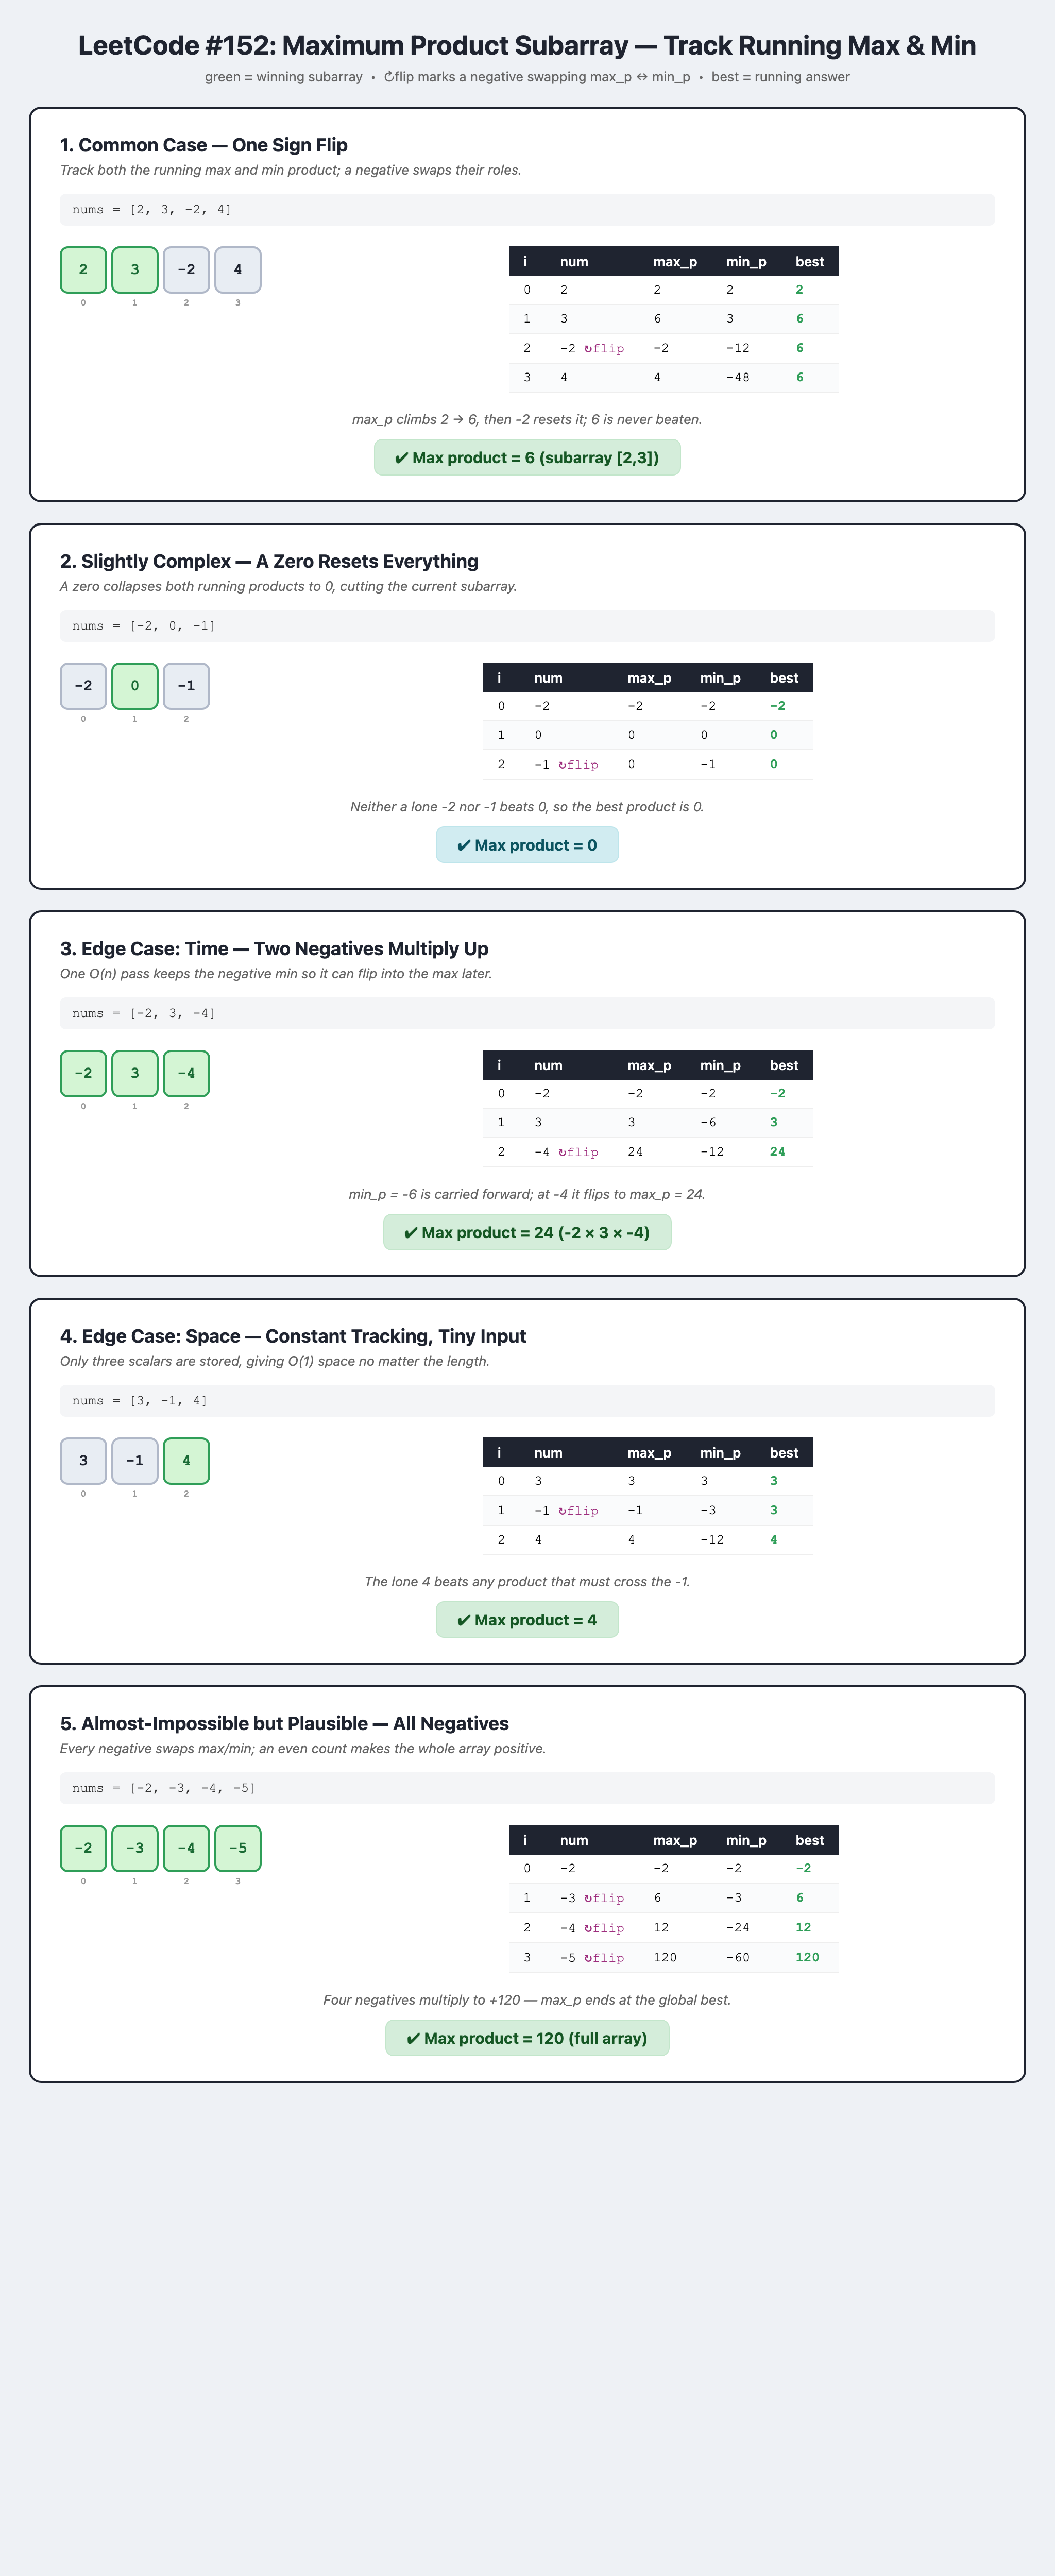

## Watch It Run

*Watch the -48 in the bottom row: it looks like the worst product so far, and one more negative turns it into the answer, 48.*

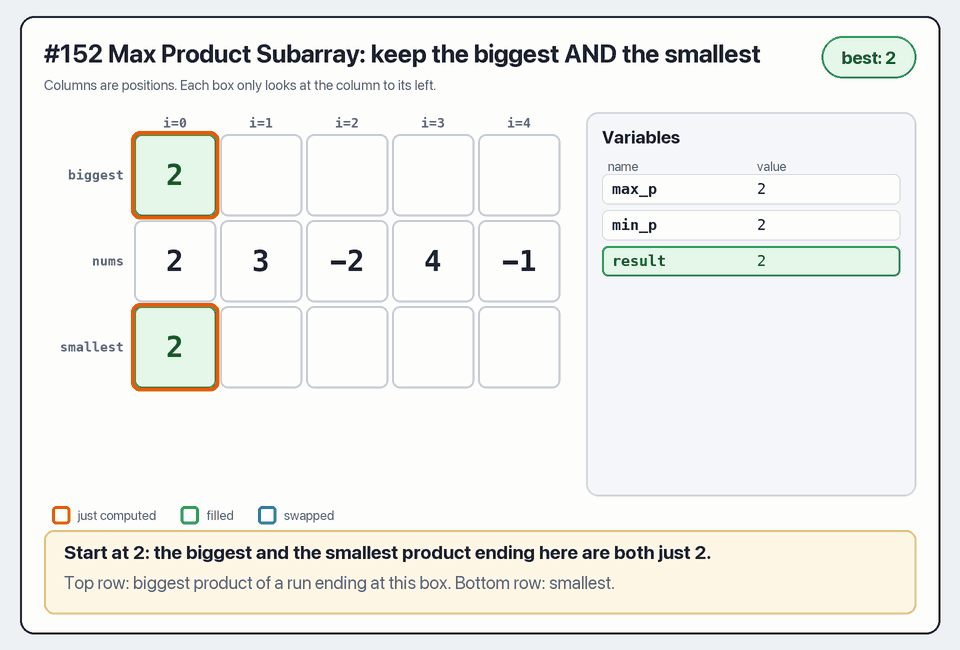